# Clasificación de texto: quejas ciudadanas

```
Textos → TF-IDF → Clasificador → Evaluación → Errores → Nuevos textos
```

Objetivo: asignar a cada queja ciudadana una categoría de servicio público.

**Sobre los datos:** las 75 quejas de esta práctica están escritas a mano para el ejercicio (15 por categoría). No son registros reales. En un caso real, las quejas contienen datos personales y deben tratarse con cuidado (ver la clase de ética).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

import nltk
from nltk.corpus import stopwords

nltk.download('stopwords', quiet=True)
spanish_stopwords = stopwords.words('spanish')

## 1. Datos

In [2]:
quejas = {
    "Agua": [
        "No hay agua en mi colonia desde hace tres días",
        "El agua sale con un color café y huele mal",
        "Fuga de agua en la esquina de la calle principal",
        "El recibo del agua llegó con un cobro muy alto",
        "Se rompió la tubería y el agua corre por la banqueta",
        "Llevamos una semana con baja presión de agua en el edificio",
        "La pipa de agua no llegó a la colonia otra vez",
        "Hay una coladera tapada y el agua se encharca",
        "El drenaje está tapado y sale agua negra a la calle",
        "Cortaron el suministro de agua sin avisar",
        "El agua potable tiene sabor raro desde ayer",
        "Un medidor de agua está roto y no registra el consumo",
        "La válvula del agua de la calle está descompuesta",
        "Piden reparar la fuga de agua que sale del hidrante",
        "No tenemos agua para lavar ni para cocinar",
    ],
    "Alumbrado": [
        "La lámpara de la calle lleva un mes apagada",
        "El poste de luz de la esquina parpadea toda la noche",
        "Hay una zona oscura en el parque por falta de alumbrado",
        "Se cayó un cable de luz frente a la escuela",
        "El semáforo está apagado y los autos no saben cuándo pasar",
        "Faltan focos en la calle del mercado",
        "La luminaria del puente no enciende desde la semana pasada",
        "Piden poner más postes de luz en el camino a la secundaria",
        "El alumbrado público de la colonia está fundido",
        "Un poste de luz quedó inclinado después de la tormenta",
        "La calle está muy oscura y da miedo caminar de noche",
        "Las lámparas del jardín central no prenden",
        "El foco del cruce peatonal se quemó hace días",
        "Cambien la luminaria de la cancha, ya no ilumina",
        "Hay cables de luz colgando en la avenida",
    ],
    "Baches": [
        "La calle tiene un bache enorme frente a mi casa",
        "Los baches de la avenida dañan los autos",
        "El asfalto está roto y hay agujeros por todos lados",
        "Piden bachear la calle principal de la colonia",
        "Hay un hoyo profundo en la carretera del pueblo",
        "La banqueta está hundida y hay un socavón",
        "Después de la lluvia se hizo un bache en la esquina",
        "Las calles de la zona norte están destruidas",
        "El pavimento se hundió y se formó un charco permanente",
        "Un bache provocó un accidente en el cruce",
        "Repavimenten la calle, ya no se puede transitar",
        "El camino de terracería tiene surcos muy profundos",
        "Hay grietas en el asfalto de la calle del mercado",
        "El puente peatonal tiene un hueco en el piso",
        "Reparen los baches del boulevard, son peligrosos para las motos",
    ],
    "Basura": [
        "El camión de la basura no pasó esta semana",
        "Hay bolsas de basura tiradas en el parque",
        "Se acumula la basura en el contenedor de la esquina",
        "Tiran escombros en el terreno baldío de la calle",
        "El recolector de basura pasa cada tercer día y es insuficiente",
        "Los vecinos queman basura afuera de la casa",
        "Hay un tiradero clandestino junto al río",
        "No hay botes de basura en la plaza",
        "La basura huele muy feo y atrae moscas",
        "Piden más contenedores de reciclaje en la colonia",
        "Los residuos del mercado no se han recogido",
        "Llantas y muebles viejos abandonados en la calle",
        "El barrendero no ha limpiado la avenida en semanas",
        "Hay animales muertos en la basura de la esquina",
        "Recojan las bolsas de basura que dejaron frente al canal",
    ],
    "Seguridad": [
        "Hay robos frecuentes en la colonia por la noche",
        "Vi a un grupo de personas armadas cerca de la escuela",
        "Asaltaron a una señora en la parada del camión",
        "Piden más patrullas en la zona comercial",
        "Hay peleas constantes afuera del bar de la esquina",
        "Un auto sospechoso ronda las casas todos los días",
        "Vandalizaron la fachada de la biblioteca",
        "Se escuchan disparos en la madrugada en el barrio",
        "Hay venta de drogas en el parque infantil",
        "Los vecinos están asustados por los secuestros recientes",
        "Robaron mi bicicleta afuera del edificio",
        "No hay vigilancia en la entrada del mercado",
        "Acosaron a unas estudiantes en la salida de la prepa",
        "Necesitamos cámaras de seguridad en el cruce peligroso",
        "Hay pandillas que cobran cuota a los comerciantes",
    ],
}

df = pd.DataFrame(
    [(texto, categoria) for categoria, textos in quejas.items() for texto in textos],
    columns=["texto", "categoria"],
)
print(f"Quejas: {len(df)}")
df["categoria"].value_counts()

Quejas: 75


categoria
Agua         15
Alumbrado    15
Baches       15
Basura       15
Seguridad    15
Name: count, dtype: int64

Las categorías están balanceadas (15 cada una). En datos reales casi nunca lo están, y eso cambia cómo hay que evaluar (ver c07).

## 2. Separar entrenamiento y prueba

Separamos los datos **antes** de hacer cualquier otra cosa. Usamos `stratify` para que cada categoría quede representada en ambos conjuntos (c05).

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    df["texto"], df["categoria"],
    test_size=0.25, stratify=df["categoria"], random_state=42,
)
print(f"Entrenamiento: {len(X_train)}  |  Prueba: {len(X_test)}")

Entrenamiento: 56  |  Prueba: 19


## 3. Pipeline: TF-IDF + clasificador

Un `Pipeline` une el vectorizador y el clasificador. Así el TF-IDF se ajusta **solo con los datos de entrenamiento**; si lo ajustamos con todo el conjunto, filtramos información de la prueba (fuga de datos).

In [4]:
modelo = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words=spanish_stopwords)),
    ("clf", LogisticRegression(max_iter=1000)),
])

modelo.fit(X_train, y_train)
pred = modelo.predict(X_test)

print(classification_report(y_test, pred, zero_division=0))

              precision    recall  f1-score   support

        Agua       1.00      1.00      1.00         4
   Alumbrado       0.25      0.67      0.36         3
      Baches       0.60      0.75      0.67         4
      Basura       1.00      0.50      0.67         4
   Seguridad       0.00      0.00      0.00         4

    accuracy                           0.58        19
   macro avg       0.57      0.58      0.54        19
weighted avg       0.59      0.58      0.55        19



**Cómo leer el reporte** (ver c07):
- **Eficiencia (precision):** de las quejas que el modelo asignó a una categoría, qué fracción era correcta.
- **Cobertura (recall):** de las quejas de una categoría, qué fracción encontró el modelo.
- **F1:** media armónica de ambas.

Con tan pocos datos, cada error mueve mucho el resultado. Interpreta los números con cuidado.

**Lo que muestra este resultado:** la categoría *Seguridad* no tiene ninguna predicción correcta en la prueba, y varias quejas de seguridad se clasifican como *Alumbrado*. Las quejas de seguridad usan vocabulario que casi no aparece en las otras categorías (por ejemplo, *robo* o *disparos*), así que con 15 ejemplos el modelo no aprende esa frontera. Revisa las palabras de la sección 8 para verlo.

## 4. Matriz de confusión

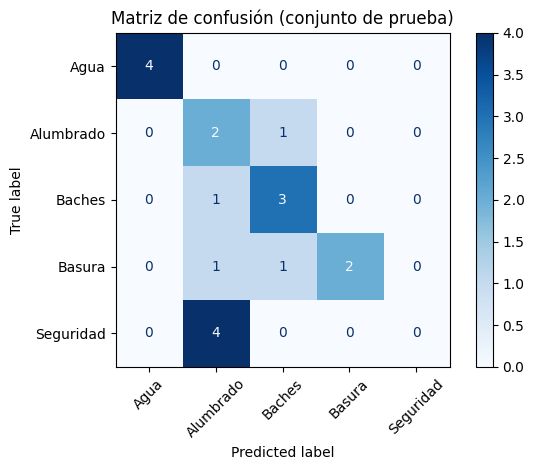

In [5]:
ConfusionMatrixDisplay.from_predictions(y_test, pred, xticks_rotation=45, cmap="Blues")
plt.title("Matriz de confusión (conjunto de prueba)")
plt.tight_layout()
plt.show()

## 5. Revisar los errores

Antes de buscar un modelo mejor, conviene leer las quejas que falla. Muchas veces el error revela una palabra ambigua o una queja que mezcla temas.

In [6]:
errores = pd.DataFrame({"texto": X_test, "real": y_test, "predicho": pred})
errores = errores[errores["real"] != errores["predicho"]]
print(f"Errores: {len(errores)} de {len(X_test)}\n")
errores

Errores: 8 de 19



,texto,real,predicho
41,El camino de terracería tiene surcos muy profu...,Baches,Alumbrado
48,Tiran escombros en el terreno baldío de la calle,Basura,Baches
19,El semáforo está apagado y los autos no saben ...,Alumbrado,Baches
67,Se escuchan disparos en la madrugada en el barrio,Seguridad,Alumbrado
71,No hay vigilancia en la entrada del mercado,Seguridad,Alumbrado
72,Acosaron a unas estudiantes en la salida de la...,Seguridad,Alumbrado
51,Hay un tiradero clandestino junto al río,Basura,Alumbrado
66,Vandalizaron la fachada de la biblioteca,Seguridad,Alumbrado


## 6. Validación cruzada

Con un solo corte de prueba, el resultado depende de qué quejas cayeron en cada lado. La validación cruzada (k-fold, c05) repite el proceso con 5 particiones distintas y da un promedio y una variación.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(modelo, df["texto"], df["categoria"], cv=cv, scoring="f1_macro")

print("F1 macro por partición:", np.round(scores, 3))
print(f"Promedio: {scores.mean():.3f}  ±  {scores.std():.3f}")

F1 macro por partición: [0.609 0.435 0.739 0.535 0.448]
Promedio: 0.553  ±  0.112


## 7. Comparar clasificadores

Como vimos en c06, cambiar el algoritmo es sencillo. Con el mismo vectorizador comparamos tres clasificadores de texto clásicos: regresión logística, Naive Bayes y SVM lineal.

In [8]:
clasificadores = {
    "Regresión logística": LogisticRegression(max_iter=1000),
    "Naive Bayes": MultinomialNB(),
    "SVM lineal": LinearSVC(),
}

for nombre, clf in clasificadores.items():
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(stop_words=spanish_stopwords)),
        ("clf", clf),
    ])
    s = cross_val_score(pipe, df["texto"], df["categoria"], cv=cv, scoring="f1_macro")
    print(f"{nombre:<22} F1 macro: {s.mean():.3f}  ±  {s.std():.3f}")

Regresión logística    F1 macro: 0.553  ±  0.112
Naive Bayes            F1 macro: 0.397  ±  0.066


SVM lineal             F1 macro: 0.564  ±  0.124


En esta ejecución, regresión logística y SVM empatan y Naive Bayes queda atrás. Con datos tan pocos, las diferencias entre clasificadores suelen ser menores que la variación entre particiones. Un empate así no permite elegir un modelo. Eso también es un resultado.

## 8. ¿Qué palabras pesan más?

La regresión logística asigna un peso a cada palabra por categoría. Revisar esos pesos nos dice si el modelo aprendió algo con sentido (por ejemplo, *agua* para Agua) o si se apoyó en un patrón accidental.

In [9]:
tfidf_fit = modelo.named_steps["tfidf"]
clf_fit = modelo.named_steps["clf"]
terminos = tfidf_fit.get_feature_names_out()

for i, categoria in enumerate(clf_fit.classes_):
    top = np.argsort(clf_fit.coef_[i])[-6:][::-1]
    print(f"{categoria:<12}: {', '.join(terminos[top])}")

Agua        : agua, sale, fuga, cocinar, lavar, tres
Alumbrado   : luz, alumbrado, luminaria, oscura, focos, faltan
Baches      : asfalto, bache, bachear, hundida, socavón, banqueta
Basura      : basura, residuos, recogido, reciclaje, contenedores, semanas
Seguridad   : afuera, patrullas, comercial, frecuentes, robos, robaron


## 9. Clasificar quejas nuevas

El modelo devuelve una probabilidad por categoría. Una queja con probabilidades parecidas entre dos categorías es ambigua, y conviene revisarla a mano.

In [10]:
nuevas = [
    "Desde ayer no sale agua caliente en mi departamento",
    "La luz de la esquina nunca prende y está muy oscuro",
    "Hay un hoyo enorme en la calle y casi caigo",
    "Alguien dejó toneladas de basura junto a la escuela",
    "Unos hombres me robaron el celular en la calle",
    "No hay agua, la basura se acumula y además la calle está oscura",
]

probs = modelo.predict_proba(nuevas)
for texto, p in zip(nuevas, probs):
    i = np.argmax(p)
    print(f"\n\"{texto}\"")
    print(f"  → {modelo.classes_[i]} ({p[i]:.0%})")


"Desde ayer no sale agua caliente en mi departamento"
  → Agua (52%)

"La luz de la esquina nunca prende y está muy oscuro"
  → Alumbrado (30%)

"Hay un hoyo enorme en la calle y casi caigo"
  → Baches (34%)

"Alguien dejó toneladas de basura junto a la escuela"
  → Basura (37%)

"Unos hombres me robaron el celular en la calle"
  → Alumbrado (23%)

"No hay agua, la basura se acumula y además la calle está oscura"
  → Basura (29%)


## Ejercicio (20 min)

1. Escribe **5 quejas nuevas** para cualquiera de las categorías y agrégalas a `quejas`. Vuelve a ejecutar desde la sección 1 y observa si cambian el F1.
2. Escribe una queja que mezcle dos categorías (como la última del ejemplo). ¿Qué probabilidad le asigna el modelo a cada una?
3. Cambia `test_size` a 0.4. ¿Cambia el ranking de clasificadores?
4. Discute: ¿qué pasaría si el modelo se usara para priorizar quejas de seguridad? ¿Qué error sería más costoso: no detectar una queja de seguridad, o enviar una de agua a seguridad? (Esto conecta con eficiencia y cobertura, c07, y con ética, c10.)

## Cierre

- El flujo es el mismo que en c05–c07: separar, entrenar, evaluar y revisar errores.
- La representación (TF-IDF) cambia; el razonamiento no.
- Los números con pocos datos son frágiles. El paso más valioso suele ser leer los errores.